# PS- 5A: Caltech-101 Transfer Learning Using VGG16

Accuracy mode: 224 x 224 images, VGG16 preprocessing, more training batches, dropout, and fine tuning.


In [23]:
# a. Import packages first
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input


In [24]:
# b. Load Caltech-101 images at VGG16's preferred 224 x 224 size.
size = (224, 224)
train_ds = tf.keras.utils.image_dataset_from_directory(
    "caltech-101", validation_split=0.2, subset="training", seed=42,
    image_size=size, batch_size=16
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    "caltech-101", validation_split=0.2, subset="validation", seed=42,
    image_size=size, batch_size=16
)
class_names = train_ds.class_names


Found 9144 files belonging to 102 classes.
Using 7316 files for training.
Found 9144 files belonging to 102 classes.
Using 1828 files for validation.


In [25]:
# c and d. Load VGG16, freeze it, and add a stronger classifier.
base = VGG16(weights="vgg16_notop_weights.h5", include_top=False, input_shape=(224, 224, 3))
base.trainable = False
model = models.Sequential([
    layers.Lambda(preprocess_input),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax")
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])


In [26]:
# e and f. Train on more images for better accuracy.
history = model.fit(train_ds.take(100), validation_data=test_ds.take(10), epochs=3)


Epoch 1/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 349s 3s/step - accuracy: 0.1644 - loss: 10.7430 - val_accuracy: 0.4187 - val_loss: 4.1865
Epoch 2/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 337s 3s/step - accuracy: 0.4563 - loss: 4.3347 - val_accuracy: 0.5938 - val_loss: 2.5347
Epoch 3/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 331s 3s/step - accuracy: 0.5975 - loss: 2.3759 - val_accuracy: 0.6687 - val_loss: 1.6510


In [27]:
# g. Evaluate loss and accuracy.
loss, accuracy = model.evaluate(test_ds.take(10))
print("Loss:", loss)
print("Accuracy:", accuracy)


10/10 ━━━━━━━━━━━━━━━━━━━━ 30s 3s/step - accuracy: 0.6375 - loss: 1.8205
Loss: 1.8204625844955444
Accuracy: 0.637499988079071


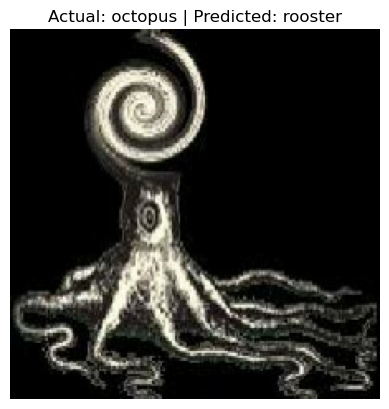

In [28]:
# h. Show one prediction.
for images, labels in test_ds.take(1):
    prediction = tf.argmax(model.predict(images[:1], verbose=0)[0]).numpy()
    plt.imshow(images[0].numpy().astype("uint8"))
    plt.title("Actual: " + class_names[labels[0]] + " | Predicted: " + class_names[prediction])
    plt.axis("off")
    plt.show()


In [ ]:
# i. Fine tune the top VGG16 layers with a small learning rate.
base.trainable = True
for layer in base.layers[:-6]:
    layer.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(train_ds.take(100), validation_data=test_ds.take(10), epochs=1)


 18/100 ━━━━━━━━━━━━━━━━━━━━ 5:36 4s/step - accuracy: 0.6771 - loss: 1.6331